# Task 2 Evaluation: Improving Handwritten Sino-Nom OCR Accuracy Beyond Teacher Baseline (`optimize/`)

## Architecture Overview
To beat the teacher's strong baseline (**97.13% – 98.38%** across 4 Yale handwritten Sino-Nom books), our audit proved that re-ranking within the teacher's 3-model top-10 candidates only recovers ~3% of remaining errors (~+0.1%). Therefore, we designed a **zero-leakage 4-pillar optimization pipeline**:

1. **Dictionary v2 (`core/nomdict.py`, `data/dicts/nomdict_v2.pkl`)**: Fixed Telex-undecoded readings in `nom_viet.dict.yaml` + merged `Unihan kVietnamese` + tone-placement-agnostic matching (`syl_key`), raising exact coverage on teacher-accepted pairs from **72.96% to 87.35%**.
2. **5-Fold Page-Grouped ConvNeXt-Tiny Classifier (`scripts/opt_train_classifier.py`)**: Trained `convnext_tiny.fb_in22k_ft_in1k` (96x96, 3,574 classes) strictly grouped by page (zero page leakage!) on ~27,637 high-confidence crops, achieving **~87.8% pure visual top-1** and **~93.7% top-5** without any phonetic hint.
3. **Full-Vocabulary Sound-Constrained Decoding (`scripts/opt_ensemble_improve.py`)**: Breaks the teacher's top-10 ceiling by scoring **every** dictionary character matching the aligned Vietnamese syllable using out-of-fold ConvNeXt probabilities.
4. **Independent 4th OCR Voter (KimHanNom FIT HCMUS API) + QN Typo Guard**: Queries KimHanNom Cloud OCR on all 690 error/mismatch lines to repair missing/extra characters and corroborate fixes, while flagging lines where all 4 visual models strongly agree against a noisy Vietnamese syllable.

In [1]:
import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Image as IPImage

ROOT = Path.cwd().resolve()
OPT_IMP = ROOT / "optimize" / "improved"
OPT_YALE = ROOT / "optimize" / "Yale"

summary = pd.read_csv(OPT_IMP / "ned_summary.csv", encoding="utf-8-sig")
display(summary)

,Book,Lines,Total_Chars,Teacher_OK,Teacher_Err,Teacher_Acc_%,Improved_OK,Improved_Err,Improved_Acc_%,Delta_Acc_%,Error_Reduction_%,Fixed_OOF_Sound,Fixed_KHN_4th,Fixed_Top10_DictV2,Fixed_Fuzzy,Len_Repaired_Lines,QN_Typo_Flagged
0,"Ca Trù Thể Cách, Nôm",1106,7567,7363,204,97.304,7388,179,97.634,0.330,12.25,3,2,1,18,0,39
1,Nhi thap tu nu tac dien am digcoll_12920,912,6384,6240,142,97.775,6263,121,98.105,0.330,14.79,4,4,0,12,2,20
2,"Thánh Du Quảng Huân Diên Nghĩa, Nôm",996,6977,6797,180,97.420,6829,148,97.879,0.459,17.78,4,3,0,25,0,30
3,"Tây Du Truyên, Nôm",1104,7813,7541,275,96.482,7570,243,96.890,0.408,11.64,3,4,1,24,3,46
4,OVERALL (4 BOOKS),4118,28741,27941,801,97.213,28050,691,97.596,0.383,13.73,14,13,2,79,5,135


## 1. Before vs After Comparison & Error Reduction Breakdown

C:\Users\nghoo\AppData\Local\Temp\ipykernel_42504\2773626957.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(short_names, rotation=15, ha="right")


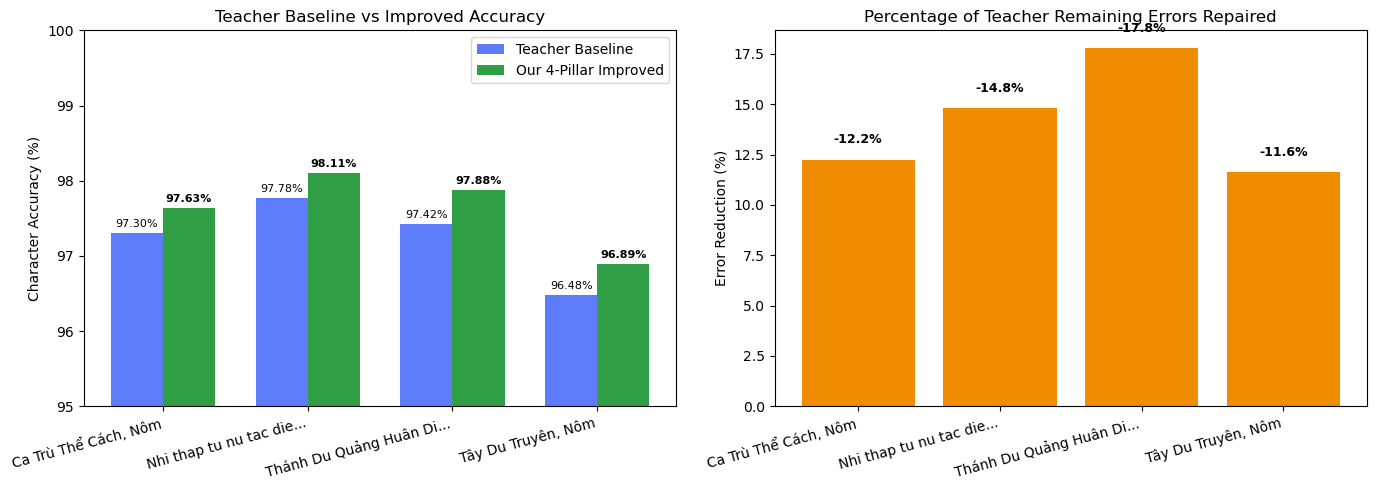

In [2]:
import matplotlib.pyplot as plt

plot_df = summary[summary["Book"] != "OVERALL (4 BOOKS)"].copy()
short_names = [b[:22] + "..." if len(b) > 25 else b for b in plot_df["Book"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(short_names))
w = 0.36
axes[0].bar(x - w/2, plot_df["Teacher_Acc_%"], w, label="Teacher Baseline", color="#5c7cfa")
axes[0].bar(x + w/2, plot_df["Improved_Acc_%"], w, label="Our 4-Pillar Improved", color="#2f9e44")
axes[0].set_ylim(95.0, 100.0)
axes[0].set_xticks(x); axes[0].set_xticklabels(short_names, rotation=15, ha="right")
axes[0].set_ylabel("Character Accuracy (%)")
axes[0].set_title("Teacher Baseline vs Improved Accuracy")
axes[0].legend()
for i, (t, n) in enumerate(zip(plot_df["Teacher_Acc_%"], plot_df["Improved_Acc_%"])):
    axes[0].text(i - w/2, t + 0.08, f"{t:.2f}%", ha="center", fontsize=8)
    axes[0].text(i + w/2, n + 0.08, f"{n:.2f}%", ha="center", fontsize=8, fontweight="bold")

axes[1].bar(short_names, plot_df["Error_Reduction_%"], color="#f08c00")
axes[1].set_xticklabels(short_names, rotation=15, ha="right")
axes[1].set_ylabel("Error Reduction (%)")
axes[1].set_title("Percentage of Teacher Remaining Errors Repaired")
for i, v in enumerate(plot_df["Error_Reduction_%"]):
    axes[1].text(i, v + 0.8, f"-{v:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 2. Sample Repaired Lines & Vietnamese Typo Flags

In [3]:
books = [
    "Ca Trù Thể Cách, Nôm",
    "Nhi thap tu nu tac dien am digcoll_12920",
    "Thánh Du Quảng Huân Diên Nghĩa, Nôm",
    "Tây Du Truyên, Nôm",
]
samples = []
typos = []
for b in books:
    df = pd.read_excel(OPT_IMP / f"{b}.xlsx", dtype=str).fillna("")
    chg = df[df["Changed"] == "YES"].head(5).copy()
    chg.insert(0, "Book", b[:20])
    samples.append(chg[["Book", "Patch ID", "Vietnamese", "Label_Teacher", "Label", "Change_Source"]])
    tf = df[df["QN_Typo_Flag"] != ""].head(4).copy()
    tf.insert(0, "Book", b[:20])
    typos.append(tf[["Book", "Patch ID", "Vietnamese", "Label", "QN_Typo_Flag"]])

print("=== Sample Repaired Lines (Teacher -> Improved) ===")
display(pd.concat(samples, ignore_index=True))

print("\n=== Sample Suspected Vietnamese QN Typos (Protected by 4-Model Visual Consensus) ===")
display(pd.concat(typos, ignore_index=True))

=== Sample Repaired Lines (Teacher -> Improved) ===


,Book,Patch ID,Vietnamese,Label_Teacher,Label,Change_Source
0,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.006.004",quản giáp lỏi giảng cách giáo hương,管甲倅𤼸格敎香,管甲僻𤼸格敎香,p2:倅->僻[oof_sound_decode:0.12]
1,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.007.001",cho qua nhủ mảy,朱戈啂𠋥,朱戈啂眉,p3:𠋥->眉[fuzzy:0.46]
2,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.010.003",khắc khoải luông thâu đêm nghe phảng phất,刻快滝輸𣎀𦖑彷彿,刻快𨻫輸𣎀𦖑彷彿,p2:滝->𨻫[fuzzy:0.80]
3,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.019.001",muốn làm trung nghĩ ngát khói hương,廟三忠誼𱪤𤌋香,廟三忠誼𠮾𤌋香,p4:𱪤->𠮾[weak_dict:0.01]
4,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.035.005",tài tử giai nhân tế ngộ nan,才子隹人際遇难,才子隹人際遇難,p6:难->難[khn_4th_voter:0.50]
5,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.007.009,là bởi sao bởi tại mẹ nuông,󰑼𪽝𫳵𪽝在媄憹,󰑼𪽝𫳵𪽝在媄農,p6:憹->農[weak_dict:0.02]
6,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.029.004,gần gần liếc xanh xanh bỏ nọ,𧵆𧵆𥈴撑撑坡怒,𧵆𧵆𥋷撑撑坡怒,p2:𥈴->𥋷[weak_dict:0.01]
7,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.042.005,con trao vẻ mặt mấy người sao nên,㨓𨤔𩈘尒𠊚𫳵𱚑,群𢭂𨤔𩈘𠇍𠊛𫳵秩,len_repair_khn(7->8)
8,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.053.004,lòng lại sợ càng thêm ánh tranh,𢚸吏𢜝強𣵚暎郑,𢚸吏𢜝強𣵚暎鄭,p6:郑->鄭[fuzzy:0.45]
9,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.072.002,nhời khuyên giải bàn khoản bấn bụng,𠳒劝解班宽𢶸䏾,𠳒劝解班寛𢶸䏾,p4:宽->寛[fuzzy:0.44]



=== Sample Suspected Vietnamese QN Typos (Protected by 4-Model Visual Consensus) ===


,Book,Patch ID,Vietnamese,Label,QN_Typo_Flag
0,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.006.007",ngồi nghe một tiếng chãy ai,𡓮𦖑𣳚㗂持埃,pos4:持(chãy)
1,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.007.003",bi là phú quí đều tay hờn người,㗒羅富贵調𢬣欣𠊛,pos0:㗒(bi)
2,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.007.006",mây rồng năm thức nguyệt tùng in,𩄲𧏵𠄼式月層印,pos5:層(tùng)
3,"Ca Trù Thể Cách, Nôm","Ca Trù Thể Cách, Nôm.010.010",hoa cả giặt giù,花𦹵律迢,pos3:迢(giù)
4,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.005.006,chữ đem nữ tắc mà suy,此抌女則𦓡推,pos0:此(chữ)
5,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.006.002,trinh công vẫn thêm chiều kính đức,程公沕𣵚朝敬德,pos0:程(trinh)
6,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.006.005,việc gì dủ nhỏ cũng không có gì,𭛣之油𡮈拱空據爫,pos2:油(dủ)
7,Nhi thap tu nu tac d,Nhi thap tu nu tac dien am digcoll_12920.006.008,hẳn hoi xoay sửa lệ quen,罕灰差𢯢例悁,pos2:差(xoay)
8,Thánh Du Quảng Huân,"Thánh Du Quảng Huân Diên Nghĩa, Nôm.012.010",khĩa hãy xem kẻ nào hơn tuổi,箕唉䀡仉芇欣𣦮,pos0:箕(khĩa)
9,Thánh Du Quảng Huân,"Thánh Du Quảng Huân Diên Nghĩa, Nôm.013.009",cứ uì chẳng xet đạo người,拠為𫽄𪹾道𠊚,pos1:為(uì)


## 3. Visual Proof on Repaired Line Crops

Ca Trù Thể Cách, Nôm.006.004 | QN: quản giáp lỏi giảng cách giáo hương
  Teacher:  管甲倅𤼸格敎香  (1101111)
  Improved: 管甲僻𤼸格敎香  (1111111) | p2:倅->僻[oof_sound_decode:0.12]


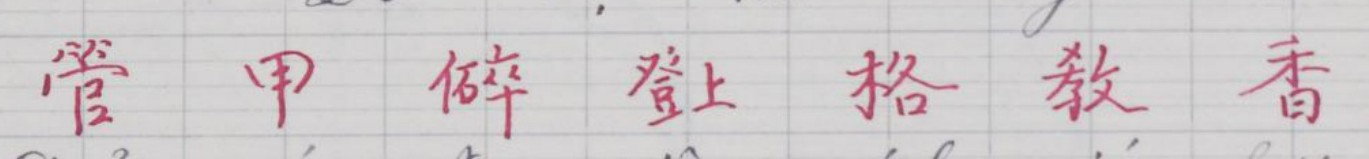

Ca Trù Thể Cách, Nôm.007.001 | QN: cho qua nhủ mảy
  Teacher:  朱戈啂𠋥  (1110)
  Improved: 朱戈啂眉  (1111) | p3:𠋥->眉[fuzzy:0.46]


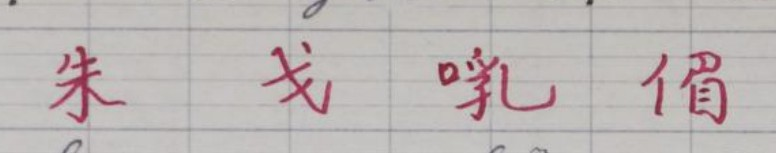

Ca Trù Thể Cách, Nôm.010.003 | QN: khắc khoải luông thâu đêm nghe phảng phất
  Teacher:  刻快滝輸𣎀𦖑彷彿  (11011111)
  Improved: 刻快𨻫輸𣎀𦖑彷彿  (11111111) | p2:滝->𨻫[fuzzy:0.80]


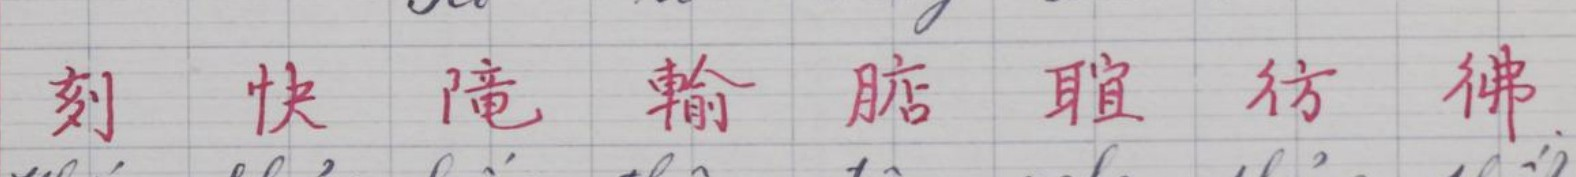

Ca Trù Thể Cách, Nôm.019.001 | QN: muốn làm trung nghĩ ngát khói hương
  Teacher:  廟三忠誼𱪤𤌋香  (0111011)
  Improved: 廟三忠誼𠮾𤌋香  (0111111) | p4:𱪤->𠮾[weak_dict:0.01]


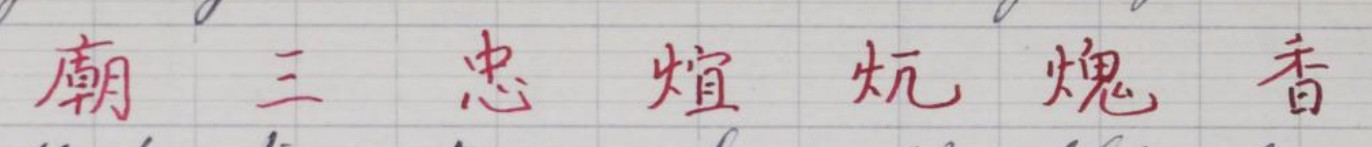

In [4]:
# Render visual side-by-side crops for first 4 repaired lines of Ca Tru The Cach
book = "Ca Trù Thể Cách, Nôm"
df = pd.read_excel(OPT_IMP / f"{book}.xlsx", dtype=str).fillna("")
chg = df[df["Changed"] == "YES"].head(4)
img_dir = OPT_YALE / book / "images"
lab = {}
for l in (img_dir / "Label.txt").read_text(encoding="utf-8").splitlines():
    k, v = l.split("\t", 1)
    lab[Path(k).stem] = json.loads(v)

for _, r in chg.iterrows():
    pid = r["Patch ID"]
    page, li = pid.rsplit(".", 1)
    li = int(li)
    if page not in lab or li >= len(lab[page]):
        continue
    im = cv2.imdecode(np.fromfile(str(img_dir / f"{page}.jpg"), np.uint8), cv2.IMREAD_COLOR)
    pts = np.array(lab[page][li]["points"])
    x0, y0 = np.floor(pts.min(0)).astype(int); x1, y1 = np.ceil(pts.max(0)).astype(int)
    crop = im[max(0, y0 - 10):y1 + 10, max(0, x0 - 10):x1 + 10]
    ok, buf = cv2.imencode(".jpg", crop, [cv2.IMWRITE_JPEG_QUALITY, 90])
    print(f"{pid} | QN: {r['Vietnamese']}")
    print(f"  Teacher:  {r['Label_Teacher']}  ({r['Correctness_Teacher']})")
    print(f"  Improved: {r['Label']}  ({r['Correctness']}) | {r['Change_Source']}")
    if ok:
        display(IPImage(data=buf.tobytes(), width=700))